# Libraries and Data

In [40]:
import pandas as pd
pd.set_option('Display.max_columns', None)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

import shap

In [41]:
PROJECT_ROOT = Path().parent.parent

data = pd.read_excel(PROJECT_ROOT / "data" / 'Survey_Logistics_Dataset_200 (1).xlsx')
df = pd.DataFrame(data)

print(f"Dataset Shape= Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print(f"Dataset Columns: {df.columns.tolist()}")
print(f"Dataset Info: \n{df.info()}")
print("Dataset Description:")
display(df.describe(include='all'))
print("Dataset Head:")
display(df.head())

Dataset Shape= Rows: 200, Columns: 19
Dataset Columns: ['date', 'origin_park', 'day_of_the_week', 'day_name', 'destination', 'respondent_type', 'age_group', 'vehicle_type', 'package_size', 'parcel_weight', 'tracking_status', 'weather_delay_experience', 'top_challenge', 'pricing_determination_metric', 'overall_system_impression', 'qualitative_suggested_improvements', 'is_festive_period', 'fuel_price_per_litre', 'price_ngn']
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 19 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   date                                200 non-null    str  
 1   origin_park                         200 non-null    str  
 2   day_of_the_week                     200 non-null    int64
 3   day_name                            200 non-null    str  
 4   destination                         200 non-null    str  
 5   respondent_type                  

,date,origin_park,day_of_the_week,day_name,destination,respondent_type,age_group,vehicle_type,package_size,parcel_weight,tracking_status,weather_delay_experience,top_challenge,pricing_determination_metric,overall_system_impression,qualitative_suggested_improvements,is_festive_period,fuel_price_per_litre,price_ngn
count,200,200,200.000000,200,200,200,200,200,200,200,200,166,200,200,200,200,200,200.000000,200.00000
unique,9,5,NaN,5,11,2,6,2,5,6,4,5,9,7,6,15,1,NaN,NaN
top,2026/06/05,Ondo garage Akure,NaN,Friday,Lagos,Sender,41–50,small_car,medium,medium,Always,Sometimes rainfall,Criminal activities,Weight of goods,Agree,Improve communication between drivers and senders,False,NaN,NaN
freq,23,53,NaN,46,45,115,53,133,74,74,83,43,28,56,75,20,200,NaN,NaN
mean,NaN,NaN,4.780000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1235.600000,5496.50000
std,NaN,NaN,1.311564,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.857031,2485.15952
min,NaN,NaN,3.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1200.000000,1500.00000
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1200.000000,3500.00000
50%,NaN,NaN,5.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1200.000000,5000.00000
75%,NaN,NaN,6.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1280.000000,7000.00000


Dataset Head:


,date,origin_park,day_of_the_week,day_name,destination,respondent_type,age_group,vehicle_type,package_size,parcel_weight,tracking_status,weather_delay_experience,top_challenge,pricing_determination_metric,overall_system_impression,qualitative_suggested_improvements,is_festive_period,fuel_price_per_litre,price_ngn
0,2026/06/03,Ilesha garage Akure,3,Wednesday,Lagos,Sender,18–25,small_car,large,heavy,Sometimes,Sometimes rainfall,Fuel scarcity,"Distance, Weight, Fuel cost combo",Agree,Reduce pricing disputes through transparency,False,1280,8500
1,2026/06/03,Ilesha garage Akure,3,Wednesday,Ilesha,Sender,36–40,small_car,small,light,Always,Flooding,Inaccurate addresses,Weight of goods,Neutral,Allow cashless payment options,False,1280,3500
2,2026/06/03,Ilesha garage Akure,3,Wednesday,Lagos,Driver,36–40,small_car,medium,medium,Sometimes,Heavy rain,Criminal activities,"Distance, Weight, Fuel cost combo",Agree,Better customer support when goods are delayed,False,1280,7000
3,2026/06/03,Northgate Akure,3,Wednesday,Ife,Driver,36–40,big_bus,large,heavy,Always,Heavy rain,Fuel scarcity,Distance only,Agree,Improve fuel subsidy to reduce transport cost,False,1280,6500
4,2026/06/03,Northgate Akure,3,Wednesday,Ibadan,Driver,36–40,small_car,large,heavy,Always,Flooding,Criminal activities,"Distance, Weight, Fuel cost combo",Neutral,Ensure drivers are vetted properly,False,1280,5500


# Data Cleaning

In [42]:
# Rearrange the dataset in chronological order based on the 'date' column for later time series analysis and visualization.
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(by='date').reset_index(drop=True)

# Drop unknown rows in age group
df = df[df['age_group'] != 'unknown']
# df["age_group"] = df["age_group"].replace("unknown", np.nan)

# Swap small_car for big_bus in vehicle_type column to make it more intuitive for analysis
df['vehicle_type'] = df['vehicle_type'].replace({'small_car': 'big_bus', 'big_bus': 'small_car'})

# Feature Engineering

In [43]:
SIZE_MAP = {
    "envelope":    {"length": 35, "width": 25, "height": 3,  "volume_cm3": 2_625},
    "small":       {"length": 40, "width": 30, "height": 25, "volume_cm3": 30_000},
    "medium":      {"length": 50, "width": 40, "height": 35, "volume_cm3": 70_000},
    "large":       {"length": 70, "width": 50, "height": 50, "volume_cm3": 175_000},
    "extra_large": {"length": 100, "width": 60, "height": 60, "volume_cm3": 360_000},
}

WEIGHT_MAP = {
    "very_light": 1.0,
    "light":      3.5,
    "medium":     10.0,
    "heavy":      22.0,
    "very_heavy": 40.0,
}

def engineer_features(df):
    df = df.copy()

    # Map categories to numbers
    df["weight_kg"] = df["parcel_weight"].map(WEIGHT_MAP)
    df["volume_cm3"] = df["package_size"].map({k: v["volume_cm3"] for k, v in SIZE_MAP.items()})

    # Density
    df["density"] = df["weight_kg"] / (df["volume_cm3"] / 1_000_000)

    # Temporal
    df["is_weekend"] = df["day_of_the_week"].isin([5, 6]).astype(int)

    # Vehicle encoding
    df["vehicle_type_encoded"] = df["vehicle_type"].map({"small_car": 0, "big_bus": 1})

    # Calculate fuel price per litre based on the date of the delivery using price average (max + min)/2 of the day
    fuel_price_per_litre_data = {
        "2026/06/03": ((1300 + 905) / 2),
        "2026/06/04": 905,
        "2026/06/05": ((1600 + 1300) / 2),
        "2026/06/06": ((1350 + 1200) / 2),
        "2026/06/17": ((1350 + 1100) / 2),
        "2026/06/18": ((1350 + 1100) / 2),
        "2026/06/19": ((1595 + 1300) / 2),
        "2026/06/20": ((1350 + 1150) / 2),
        "2026/06/21": ((1600 + 900) / 2),
    }

    df["fuel_price_per_litre"] = df["date"].dt.strftime("%Y/%m/%d").map(fuel_price_per_litre_data)

    return df

# Engineer features
df = engineer_features(df)

engineered_features = [
    "weight_kg", "volume_cm3", "density", "day_of_the_week", "is_weekend","is_festive_period", "vehicle_type_encoded", "fuel_price_per_litre"
            ]
numerical_features = ["day_of_the_week", "fuel_price_per_litre","weight_kg", "volume_cm3", "density", "is_weekend", "vehicle_type_encoded"]
categorical_features = ["is_festive_period", "qualitative_suggested_improvements", "overall_system_impression", "pricing_determination_metric", "top_challenge", "weather_delay_experience", "tracking_status", 
                        "parcel_weight", "package_size", "vehicle_type", "respondent_type", "age_group", "destination", "day_name", "origin_park"]

features = numerical_features + categorical_features

print("Dataset head (5) for engineered features:")
display(df[engineered_features].head(5))
print("\nDatashape after cleaning and engineering new features; Rows: {}, Columns: {}".format(df.shape[0], df.shape[1]))
print("Dataset Head (5) for master dataset:")
display(df.head(5))

Dataset head (5) for engineered features:


,weight_kg,volume_cm3,density,day_of_the_week,is_weekend,is_festive_period,vehicle_type_encoded,fuel_price_per_litre
0,22.0,175000,125.714286,3,0,False,1,1102.5
1,3.5,30000,116.666667,3,0,False,0,1102.5
2,10.0,70000,142.857143,3,0,False,1,1102.5
4,1.0,2625,380.952381,3,0,False,0,1102.5
5,3.5,30000,116.666667,3,0,False,1,1102.5



Datashape after cleaning and engineering new features; Rows: 180, Columns: 24
Dataset Head (5) for master dataset:


,date,origin_park,day_of_the_week,day_name,destination,respondent_type,age_group,vehicle_type,package_size,parcel_weight,tracking_status,weather_delay_experience,top_challenge,pricing_determination_metric,overall_system_impression,qualitative_suggested_improvements,is_festive_period,fuel_price_per_litre,price_ngn,weight_kg,volume_cm3,density,is_weekend,vehicle_type_encoded
0,2026-06-03,Ilesha garage Akure,3,Wednesday,Lagos,Sender,18–25,big_bus,large,heavy,Sometimes,Sometimes rainfall,Fuel scarcity,"Distance, Weight, Fuel cost combo",Agree,Reduce pricing disputes through transparency,False,1102.5,8500,22.0,175000,125.714286,0,1
1,2026-06-03,Cathedral Park Akure,3,Wednesday,Ilesha,Sender,26–35,small_car,small,light,Sometimes,Flooding,Pricing disputes,Weight of goods,Disagree,Improve communication between drivers and senders,False,1102.5,4000,3.5,30000,116.666667,0,0
2,2026-06-03,Cathedral Park Akure,3,Wednesday,Ibadan,Driver,41–50,big_bus,medium,medium,Always,Dust storm,Pricing disputes,Weight of goods,Disagree,Ensure drivers are vetted properly,False,1102.5,7000,10.0,70000,142.857143,0,1
4,2026-06-03,Cathedral Park Akure,3,Wednesday,Ibadan,Driver,41–50,small_car,envelope,very_light,Always,Harmattan,Fuel scarcity,Weight of goods,Agree,Track parcels end-to-end,False,1102.5,5000,1.0,2625,380.952381,0,0
5,2026-06-03,Roadblock Akure,3,Wednesday,Osogbo,Sender,41–50,big_bus,small,light,Sometimes,Harmattan,Inaccurate addresses,Type of goods,Disagree,Add SMS notifications for delivery status,False,1102.5,1500,3.5,30000,116.666667,0,1


# Exploratory Data Analysis (EDA)

## Distributional Profile

Distribution of Package Sizes:


respondent_type,Driver,Sender
package_size,,
envelope,6,5
extra_large,8,8
large,17,22
medium,24,42
small,25,23


Distribution of Parcel Weights:


respondent_type,Driver,Sender
parcel_weight,,
heavy,17,22
light,25,23
medium,24,42
very heavy,7,7
very_heavy,1,1
very_light,6,5


Distribution of Vehicle Type:


respondent_type,Driver,Sender
vehicle_type,,
big_bus,52,66
small_car,28,34


... (2 outputs left out)

Distribution of Origin Park:


respondent_type,Driver,Sender
origin_park,,
Cathedral Park Akure,17,21
Ilesha garage Akure,8,18
Northgate Akure,14,15
Ondo garage Akure,24,24
Roadblock Akure,17,22


Distribution of Destination Park:


respondent_type,Driver,Sender
destination,,
Abuja,1,1
Ado-Ekiti,2,2
Benin,7,15
Ibadan,9,13
Ife,12,18
Ilesha,5,10
Lagos,20,17
Ondo,9,3
Osogbo,7,9


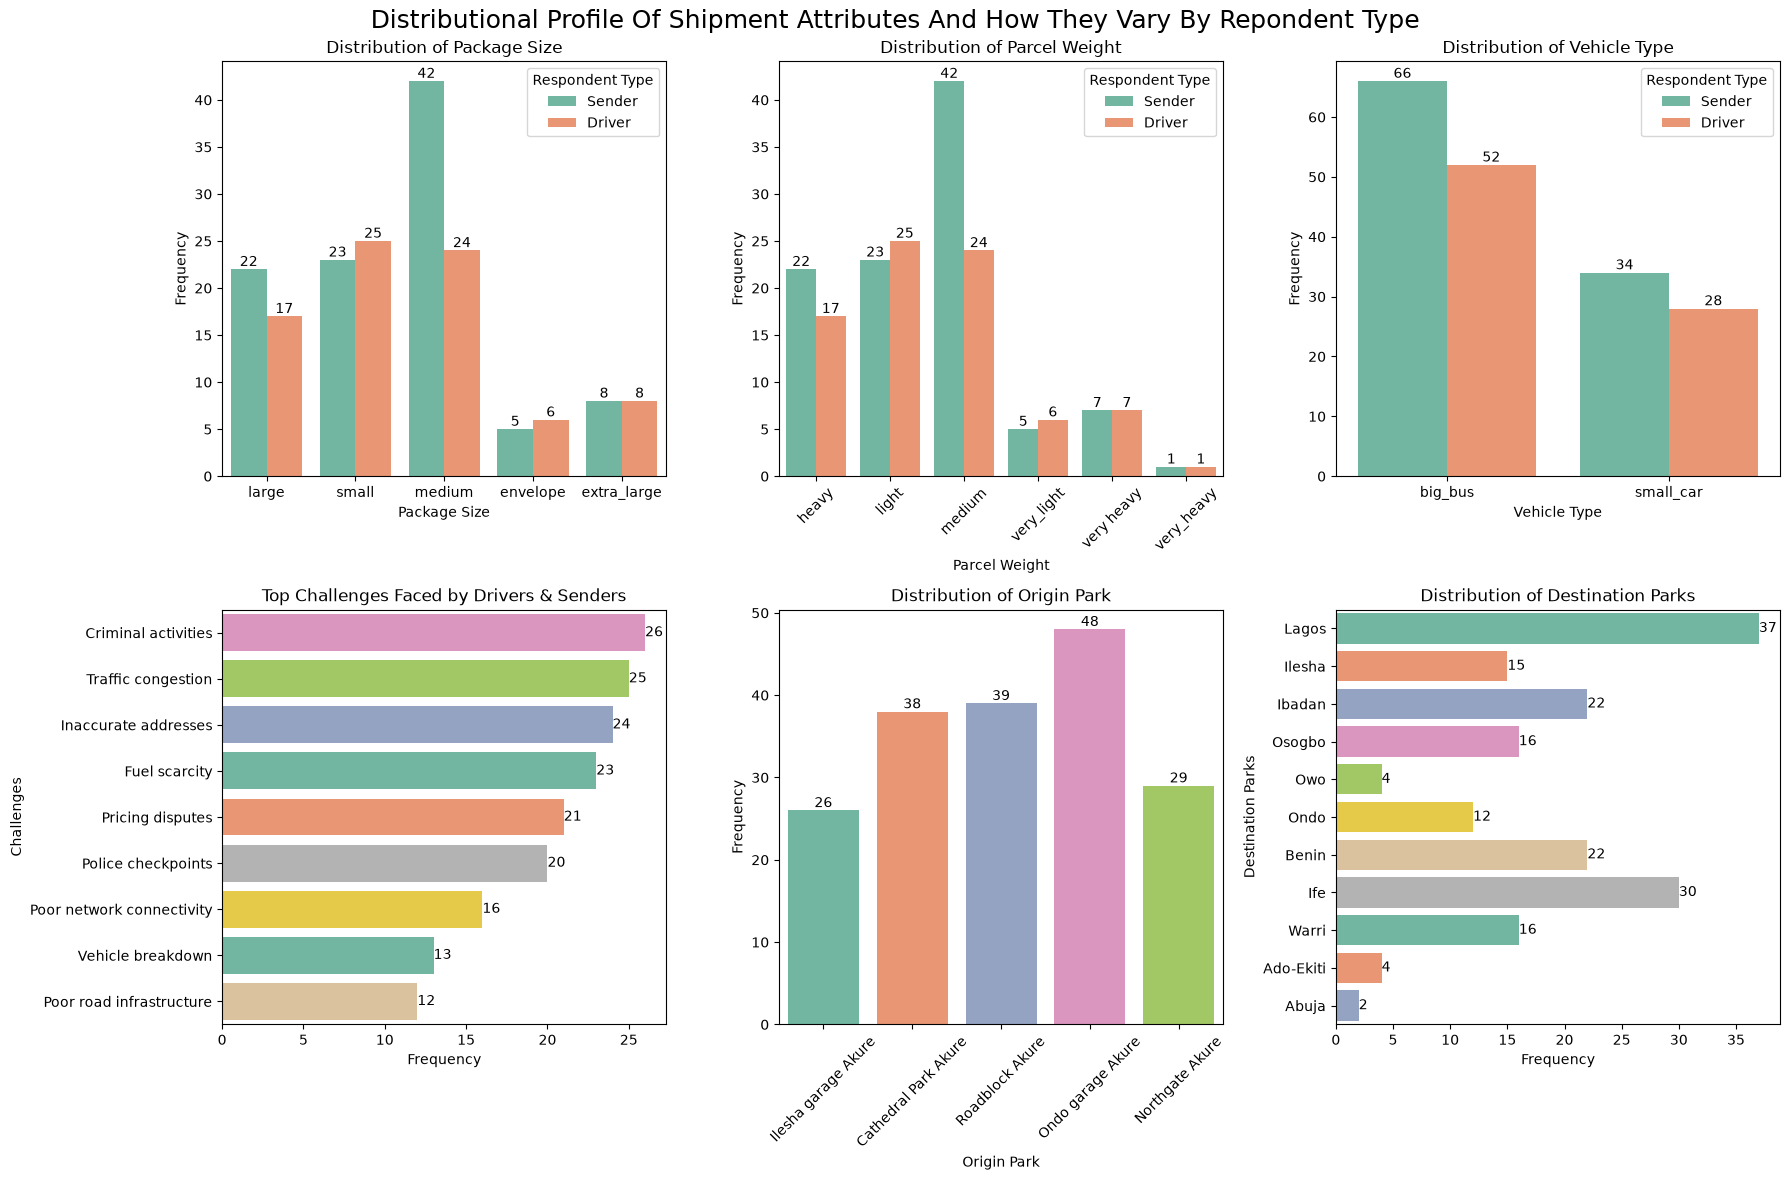

In [44]:
# Distributional profile of shipment attributes and how they vary by respondent (sender, driver)
# 1. Distribution of Package Size
package_sizes_X_respondent = df.groupby(['package_size', 'respondent_type']).size().unstack(fill_value=0)
print("Distribution of Package Sizes:")
display(package_sizes_X_respondent)

# 2. Distribution of Parcel Weight
parcel_weights_X_respondent = df.groupby(['parcel_weight', 'respondent_type']).size().unstack(fill_value=0)
print("Distribution of Parcel Weights:")
display(parcel_weights_X_respondent)

# 3. Vehicle type distribution
vehicle_type__X_respondent = df.groupby(['vehicle_type', 'respondent_type']).size().unstack(fill_value=0)
print("Distribution of Vehicle Type:")
display(vehicle_type__X_respondent)

# 4. Top challenges faced by drivers
top_challenges_X_respondent = df.groupby(['top_challenge', 'respondent_type']).size().unstack(fill_value=0)
print("Top Challenges Faced by Drivers:")
display(top_challenges_X_respondent)

# 5. Distribution of origin park
origin_park_X_respondent = df.groupby(['origin_park', 'respondent_type']).size().unstack(fill_value=0)
print("Distribution of Origin Park:")
display(origin_park_X_respondent)

# 6. Distribution of destination park
destination_park_X_respondent = df.groupby(['destination', 'respondent_type']).size().unstack(fill_value=0)
print("Distribution of Destination Park:")
display(destination_park_X_respondent)

# Visualizations
plt.figure(figsize=(18, 12))
plt.subplot(2, 3, 1)
sns.countplot(x='package_size', data=df, hue="respondent_type", palette='Set2')
plt.title('Distribution of Package Size')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel('Package Size')
plt.ylabel('Frequency')
plt.legend(title='Respondent Type')

plt.subplot(2, 3, 2)
sns.countplot(x='parcel_weight', data=df, hue="respondent_type", palette='Set2')
plt.title('Distribution of Parcel Weight')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel('Parcel Weight')
plt.xticks(rotation=45)
plt.ylabel('Frequency')
plt.legend(title='Respondent Type')

plt.subplot(2, 3, 3)
sns.countplot(x='vehicle_type', data=df, hue="respondent_type", palette='Set2')
plt.title('Distribution of Vehicle Type')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel('Vehicle Type')
plt.ylabel('Frequency')
plt.legend(title='Respondent Type')

plt.subplot(2, 3, 4)
order = df['top_challenge'].value_counts().index
sns.countplot(y='top_challenge', data=df, order=order, hue="top_challenge", palette='Set2')
plt.title('Top Challenges Faced by Drivers & Senders')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel('Frequency')
plt.ylabel('Challenges')

plt.subplot(2, 3, 5)
sns.countplot(x='origin_park', data=df, hue="origin_park", palette='Set2')
plt.title('Distribution of Origin Park')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel('Origin Park')
plt.xticks(rotation=45)
plt.ylabel('Frequency')

plt.subplot(2, 3, 6)
sns.countplot(y='destination', hue='destination', data=df, palette='Set2')
plt.title('Distribution of Destination Parks')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.ylabel('Destination Parks')
plt.xlabel('Frequency')

plt.suptitle('Distributional Profile Of Shipment Attributes And How They Vary By Repondent Type', fontsize=18)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "Distributional_Profile_Of_Shipment_Attributes_And_How_They_Vary_By_Repondent_Type.png", dpi=300, bbox_inches='tight')
plt.show()

## Operational and Contextual Factors

RESEARCH QUESTION 2: Factors Associated with Delivery Price

Price (NGN) Summary Statistics:
count      180.00
mean      5424.44
std       2452.31
min       1500.00
25%       3500.00
50%       5000.00
75%       7000.00
max      10000.00
Name: price_ngn, dtype: float64

Mean Price by Day of the Week:
              mean  median  count
day_name                         
Thursday   6190.70  5700.0     43
Friday     5577.50  5250.0     40
Saturday   5534.21  4850.0     38
Sunday     5394.74  5000.0     19
Wednesday  4357.50  3250.0     40

Mean Price by Festive Period:
                      mean  median  count
is_festive_period                        
False              5424.44  5000.0    180

Mean Price by Vehicle Type:
                 mean  median  count
vehicle_type                        
big_bus       4602.54  4000.0    118
small_car     6988.71  6700.0     62

Mean Price by Package Size:
                 mean  median  count
package_size                        
envelope      3627.27  3

c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'}

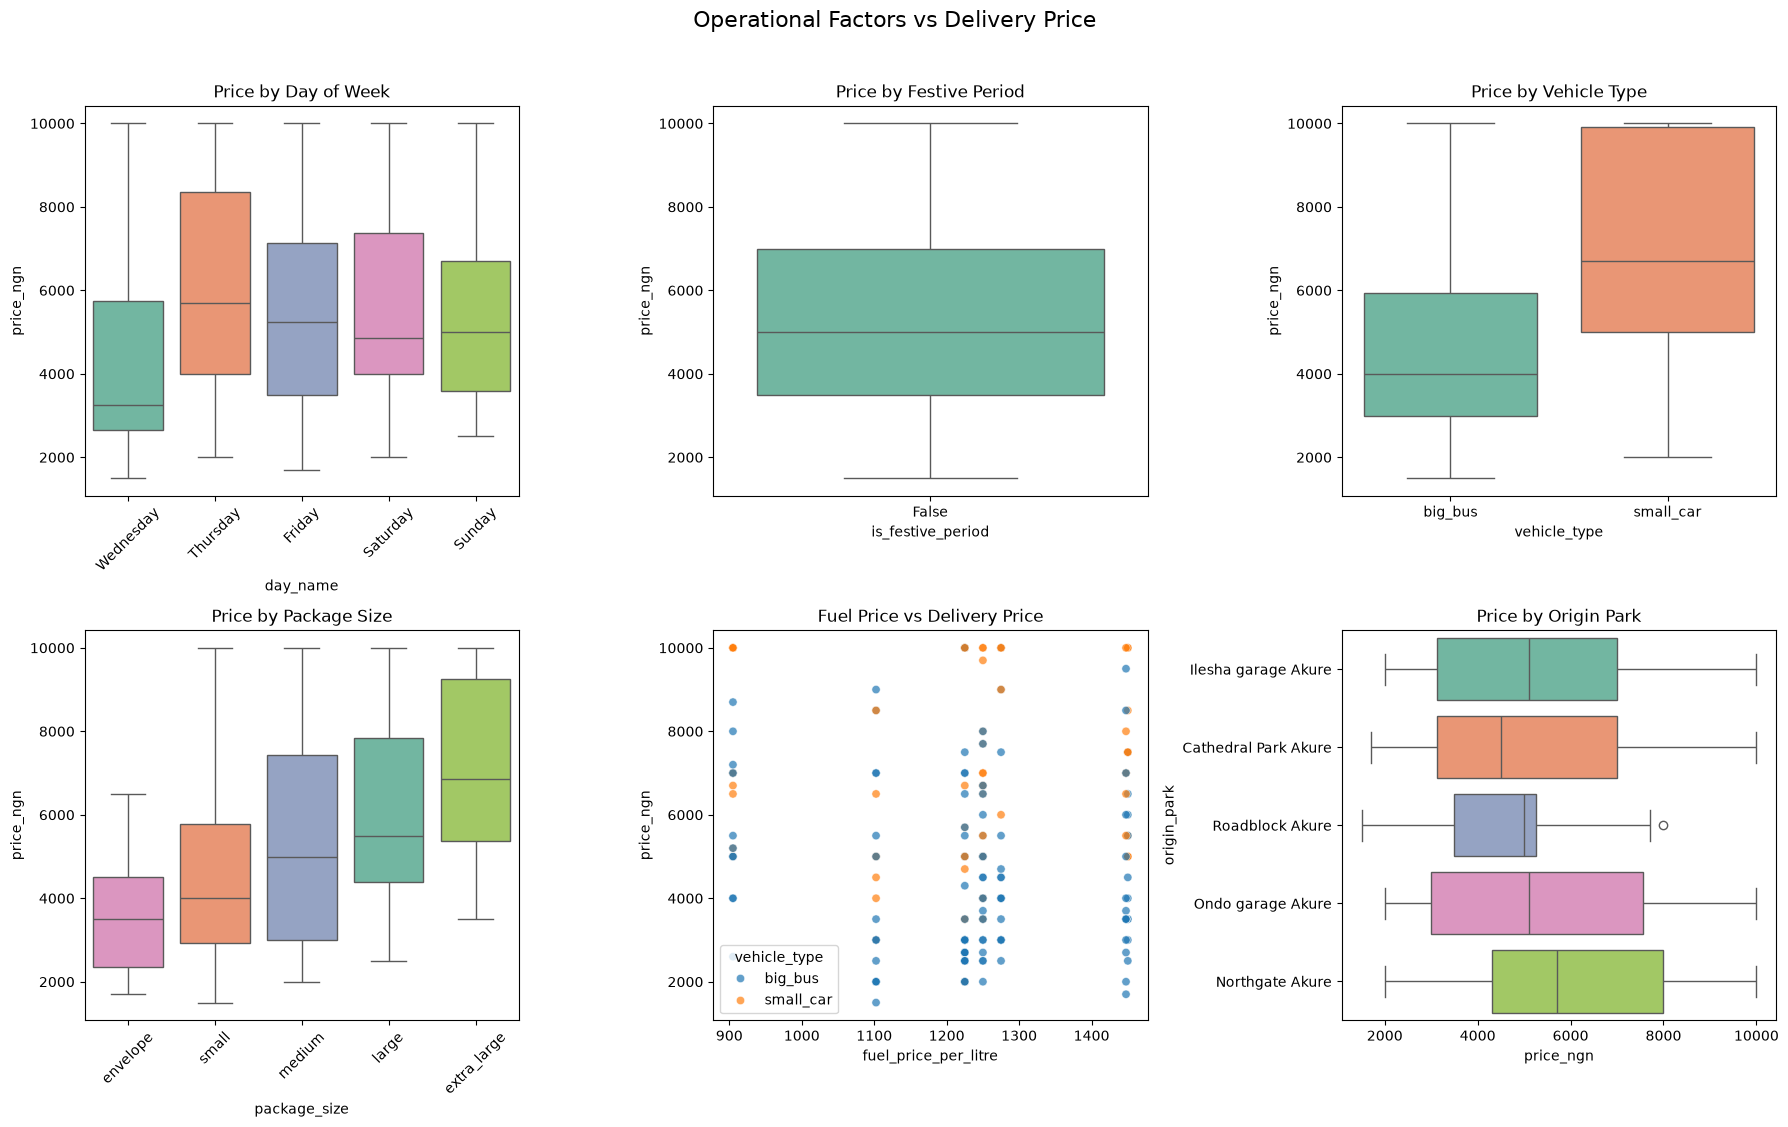

In [45]:
# ============================================================
# RESEARCH QUESTION 2
# Relationship of operational factors with delivery price
# ============================================================

print("=" * 70)
print("RESEARCH QUESTION 2: Factors Associated with Delivery Price")
print("=" * 70)

# Descriptive statistics of price
print("\nPrice (NGN) Summary Statistics:")
print(df['price_ngn'].describe().round(2))

# Mean price by key factors
print("\nMean Price by Day of the Week:")
print(df.groupby('day_name')['price_ngn'].agg(['mean', 'median', 'count']).round(2).sort_values('mean', ascending=False))

print("\nMean Price by Festive Period:")
print(df.groupby('is_festive_period')['price_ngn'].agg(['mean', 'median', 'count']).round(2))

print("\nMean Price by Vehicle Type:")
print(df.groupby('vehicle_type')['price_ngn'].agg(['mean', 'median', 'count']).round(2))

print("\nMean Price by Package Size:")
print(df.groupby('package_size')['price_ngn'].agg(['mean', 'median', 'count']).round(2))

print("\nMean Price by Origin Park:")
print(df.groupby('origin_park')['price_ngn'].agg(['mean', 'median', 'count']).round(2))

print("\nCorrelation: Fuel Price vs Delivery Price")
print(df[['fuel_price_per_litre', 'price_ngn']].corr().round(3))

# Visualization
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

sns.boxplot(data=df, x='day_name', y='price_ngn', ax=axes[0,0], palette='Set2', hue="day_name", legend=False)
axes[0,0].set_title('Price by Day of Week')
axes[0,0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='is_festive_period', y='price_ngn', ax=axes[0,1], palette='Set2', hue="is_festive_period", legend=False)
axes[0,1].set_title('Price by Festive Period')

sns.boxplot(data=df, x='vehicle_type', y='price_ngn', ax=axes[0,2], palette='Set2', hue="vehicle_type", legend=False)
axes[0,2].set_title('Price by Vehicle Type')

sns.boxplot(data=df, x='package_size', y='price_ngn', ax=axes[1,0], palette='Set2', hue="package_size", 
            order=df.groupby('package_size')['price_ngn'].median().sort_values().index, legend=False)
axes[1,0].set_title('Price by Package Size')
axes[1,0].tick_params(axis='x', rotation=45)

sns.scatterplot(data=df, x='fuel_price_per_litre', y='price_ngn', hue='vehicle_type', ax=axes[1,1], alpha=0.7)
axes[1,1].set_title('Fuel Price vs Delivery Price')

sns.boxplot(data=df, y='origin_park', x='price_ngn', ax=axes[1,2], palette='Set2', hue="origin_park", legend=False)
axes[1,2].set_title('Price by Origin Park')

plt.suptitle('Operational Factors vs Delivery Price', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "Operational_Factors_vs_Delivery_Price.png", dpi=300, bbox_inches='tight')
plt.show()

## Challenges and weather-delay experiences

RESEARCH QUESTION 3: Challenges & Weather Delay Experiences

Top Challenges (Overall):
top_challenge
Criminal activities          26
Traffic congestion           25
Inaccurate addresses         24
Fuel scarcity                23
Pricing disputes             21
Police checkpoints           20
Poor network connectivity    16
Vehicle breakdown            13
Poor road infrastructure     12
Name: count, dtype: int64

Top Challenges by Respondent Type:
top_challenge    Criminal activities  Fuel scarcity  Inaccurate addresses  \
respondent_type                                                             
Driver                          18.8           11.2                  13.8   
Sender                          11.0           14.0                  13.0   

top_challenge    Police checkpoints  Poor network connectivity  \
respondent_type                                                  
Driver                         11.2                        7.5   
Sender                         11.0       

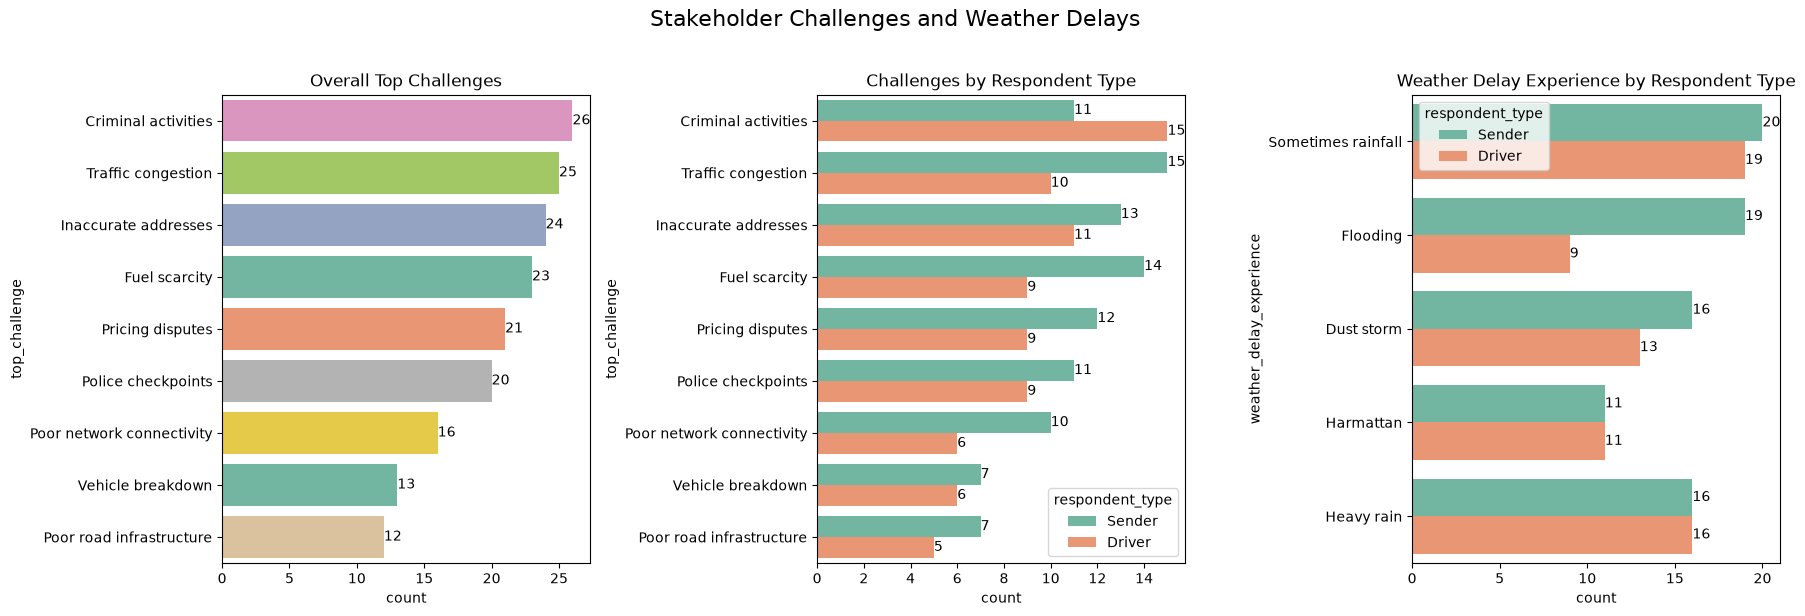

In [46]:
# ============================================================
# RESEARCH QUESTION 3
# Challenges and weather-delay experiences
# ============================================================

print("=" * 70)
print("RESEARCH QUESTION 3: Challenges & Weather Delay Experiences")
print("=" * 70)

print("\nTop Challenges (Overall):")
print(df['top_challenge'].value_counts())

print("\nTop Challenges by Respondent Type:")
print(pd.crosstab(df['respondent_type'], df['top_challenge'], normalize='index').round(3) * 100)

print("\nWeather Delay Experience (Overall):")
print(df['weather_delay_experience'].value_counts(dropna=False))

print("\nWeather Delay by Respondent Type:")
print(pd.crosstab(df['respondent_type'], df['weather_delay_experience'], normalize='index').round(3) * 100)

print("\nTop Challenges by Origin Park:")
print(pd.crosstab(df['origin_park'], df['top_challenge']))

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

order_chal = df['top_challenge'].value_counts().index
sns.countplot(data=df, y='top_challenge', order=order_chal, ax=axes[0], palette='Set2', hue="top_challenge", legend=False)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', label_type='edge')
axes[0].set_title('Overall Top Challenges')

sns.countplot(data=df, y='top_challenge', hue='respondent_type', order=order_chal, ax=axes[1], palette='Set2')
axes[1].set_title('Challenges by Respondent Type')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', label_type='edge')

sns.countplot(data=df, y='weather_delay_experience', hue='respondent_type', ax=axes[2], palette='Set2')
axes[2].set_title('Weather Delay Experience by Respondent Type')
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%d', label_type='edge')

plt.suptitle('Stakeholder Challenges and Weather Delays', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / 'Stakeholder_Challenges_and_Weather_Delays.png', dpi=300, bbox_inches='tight')
plt.show()

## Demographics, pricing metrics, and alignment with actual prices

RESEARCH QUESTION 4: Demographics & Pricing Metrics

Age Group Distribution:
age_group
41–50       53
26–35       47
36–40       42
18–25       24
Above 50    14
Name: count, dtype: int64

Stated Pricing Determination Metric:
pricing_determination_metric
Weight of goods                      51
Distance, Weight, Fuel cost combo    36
Distance only                        28
Distance, Weight, Dynamic combo      22
Dynamic pricing                      18
unknown                              16
Type of goods                         9
Name: count, dtype: int64

Mean Actual Price by Stated Pricing Metric:
                                      mean  median  count
pricing_determination_metric                             
Weight of goods                    6033.33  6000.0     51
unknown                            5856.25  5250.0     16
Dynamic pricing                    5533.33  5000.0     18
Distance, Weight, Fuel cost combo  5147.22  5000.0     36
Distance, Weight, Dynamic combo    5140.91  47

c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)
c:\Users\USER\anaconda3\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'}

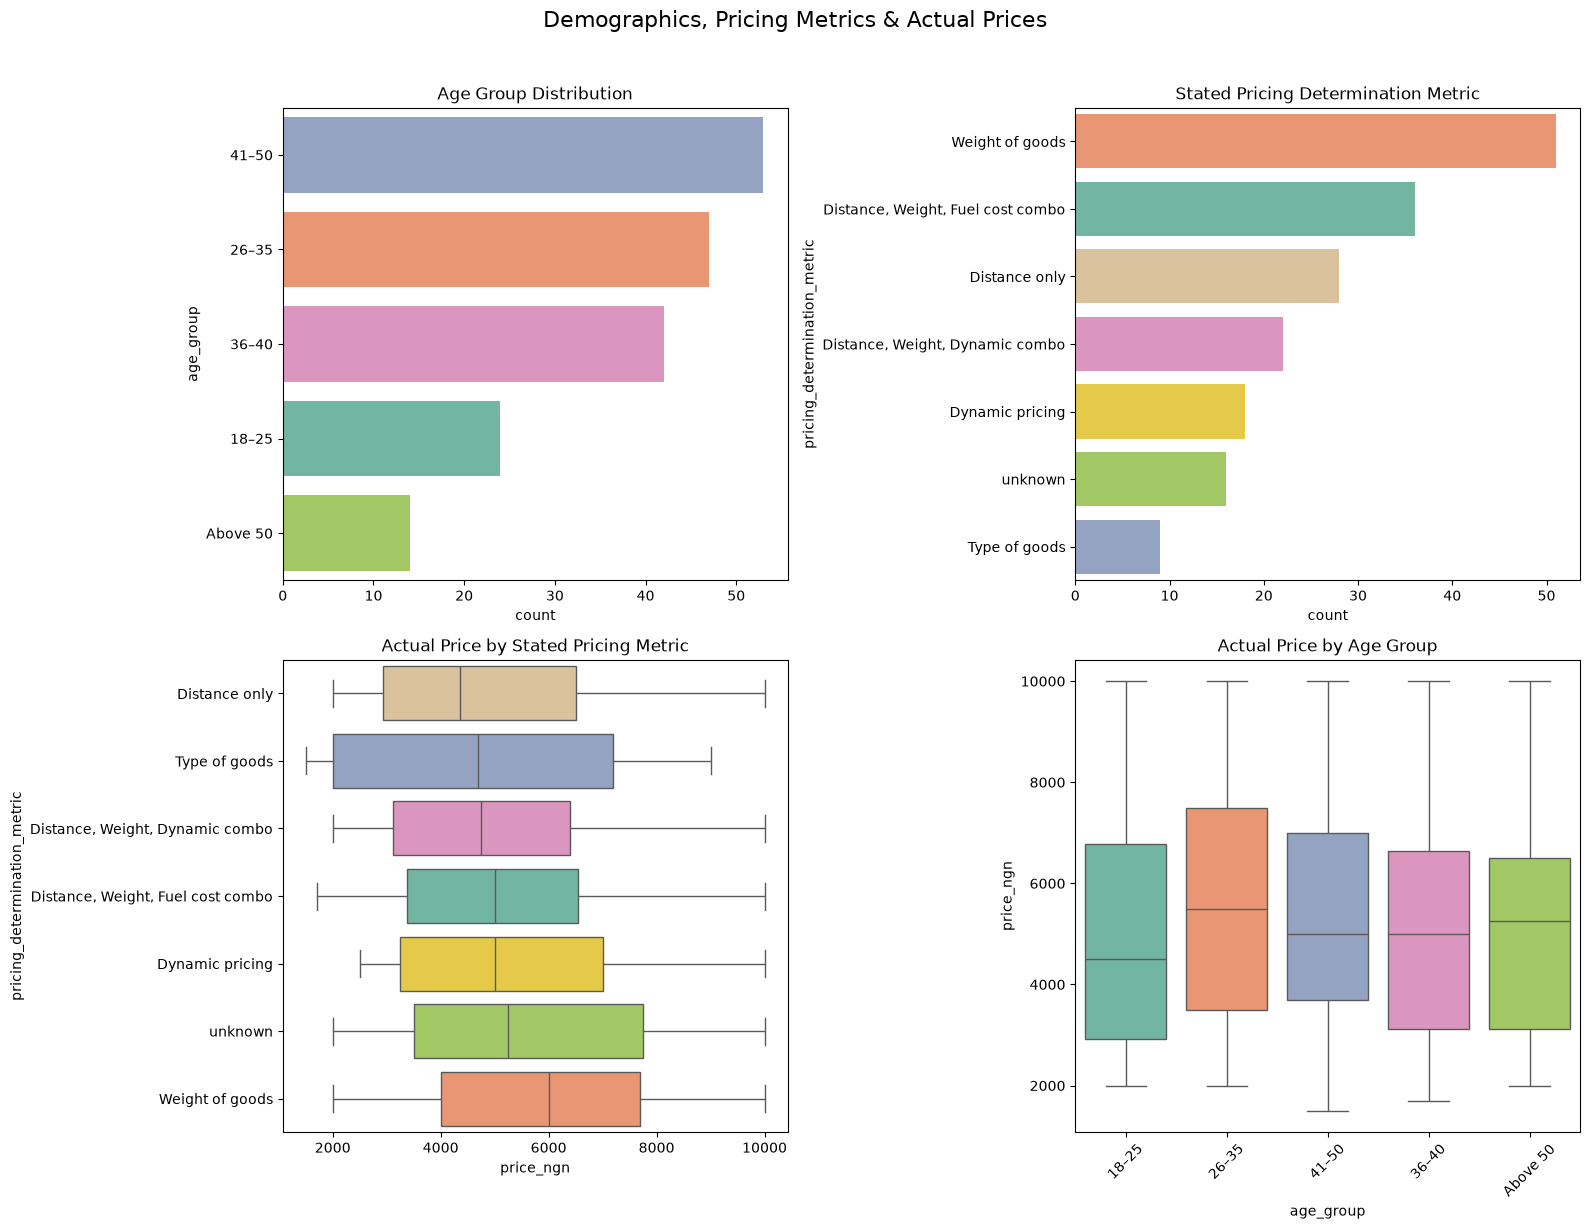

In [47]:
# ============================================================
# RESEARCH QUESTION 4
# Demographics, stated pricing metrics & actual prices
# ============================================================

print("=" * 70)
print("RESEARCH QUESTION 4: Demographics & Pricing Metrics")
print("=" * 70)

print("\nAge Group Distribution:")
print(df['age_group'].value_counts())

print("\nStated Pricing Determination Metric:")
print(df['pricing_determination_metric'].value_counts())

print("\nMean Actual Price by Stated Pricing Metric:")
print(df.groupby('pricing_determination_metric')['price_ngn'].agg(['mean', 'median', 'count']).round(2).sort_values('mean', ascending=False))

print("\nMean Price by Age Group:")
print(df.groupby('age_group')['price_ngn'].agg(['mean', 'median', 'count']).round(2))

print("\nVehicle Type by Age Group:")
print(pd.crosstab(df['age_group'], df['vehicle_type'], normalize='index').round(3) * 100)

print("\nPricing Metric by Vehicle Type:")
print(pd.crosstab(df['vehicle_type'], df['pricing_determination_metric'], normalize='index').round(3) * 100)

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=df, y='age_group', order=df['age_group'].value_counts().index, ax=axes[0,0], palette='Set2', hue="age_group", legend=False)
axes[0,0].set_title('Age Group Distribution')

sns.countplot(data=df, y='pricing_determination_metric',
              order=df['pricing_determination_metric'].value_counts().index, ax=axes[0,1], palette='Set2', hue="pricing_determination_metric", legend=False)
axes[0,1].set_title('Stated Pricing Determination Metric')

sns.boxplot(data=df, y='pricing_determination_metric', x='price_ngn', ax=axes[1,0], palette='Set2', hue="pricing_determination_metric",
            order=df.groupby('pricing_determination_metric')['price_ngn'].median().sort_values().index, legend=False)
axes[1,0].set_title('Actual Price by Stated Pricing Metric')

sns.boxplot(data=df, x='age_group', y='price_ngn', ax=axes[1,1], palette='Set2', hue="age_group", legend=False)
axes[1,1].set_title('Actual Price by Age Group')
axes[1,1].tick_params(axis='x', rotation=45)

plt.suptitle('Demographics, Pricing Metrics & Actual Prices', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "Demographics_Pricing_Metrics_&_Actual_Prices.png", dpi=300, bbox_inches='tight')
plt.show()

## System impressions, suggestions, and relationship with tracking experience

RESEARCH QUESTION 5: System Impressions & Suggestions

Overall System Impression:
overall_system_impression
Agree                69
Neutral              44
Strongly Agree       23
Disagree             21
unknown              12
Strongly Disagree    11
Name: count, dtype: int64

Tracking Status Experience:
tracking_status
Always       74
Sometimes    61
Rarely       30
Never        15
Name: count, dtype: int64

System Impression by Tracking Status:
overall_system_impression  Agree  Disagree  Neutral  Strongly Agree  \
tracking_status                                                       
Always                      35.1      14.9     14.9            14.9   
Never                       20.0      13.3     53.3             6.7   
Rarely                      56.7       3.3     23.3            13.3   
Sometimes                   37.7      11.5     29.5            11.5   

overall_system_impression  Strongly Disagree  unknown  
tracking_status                                        
Always   

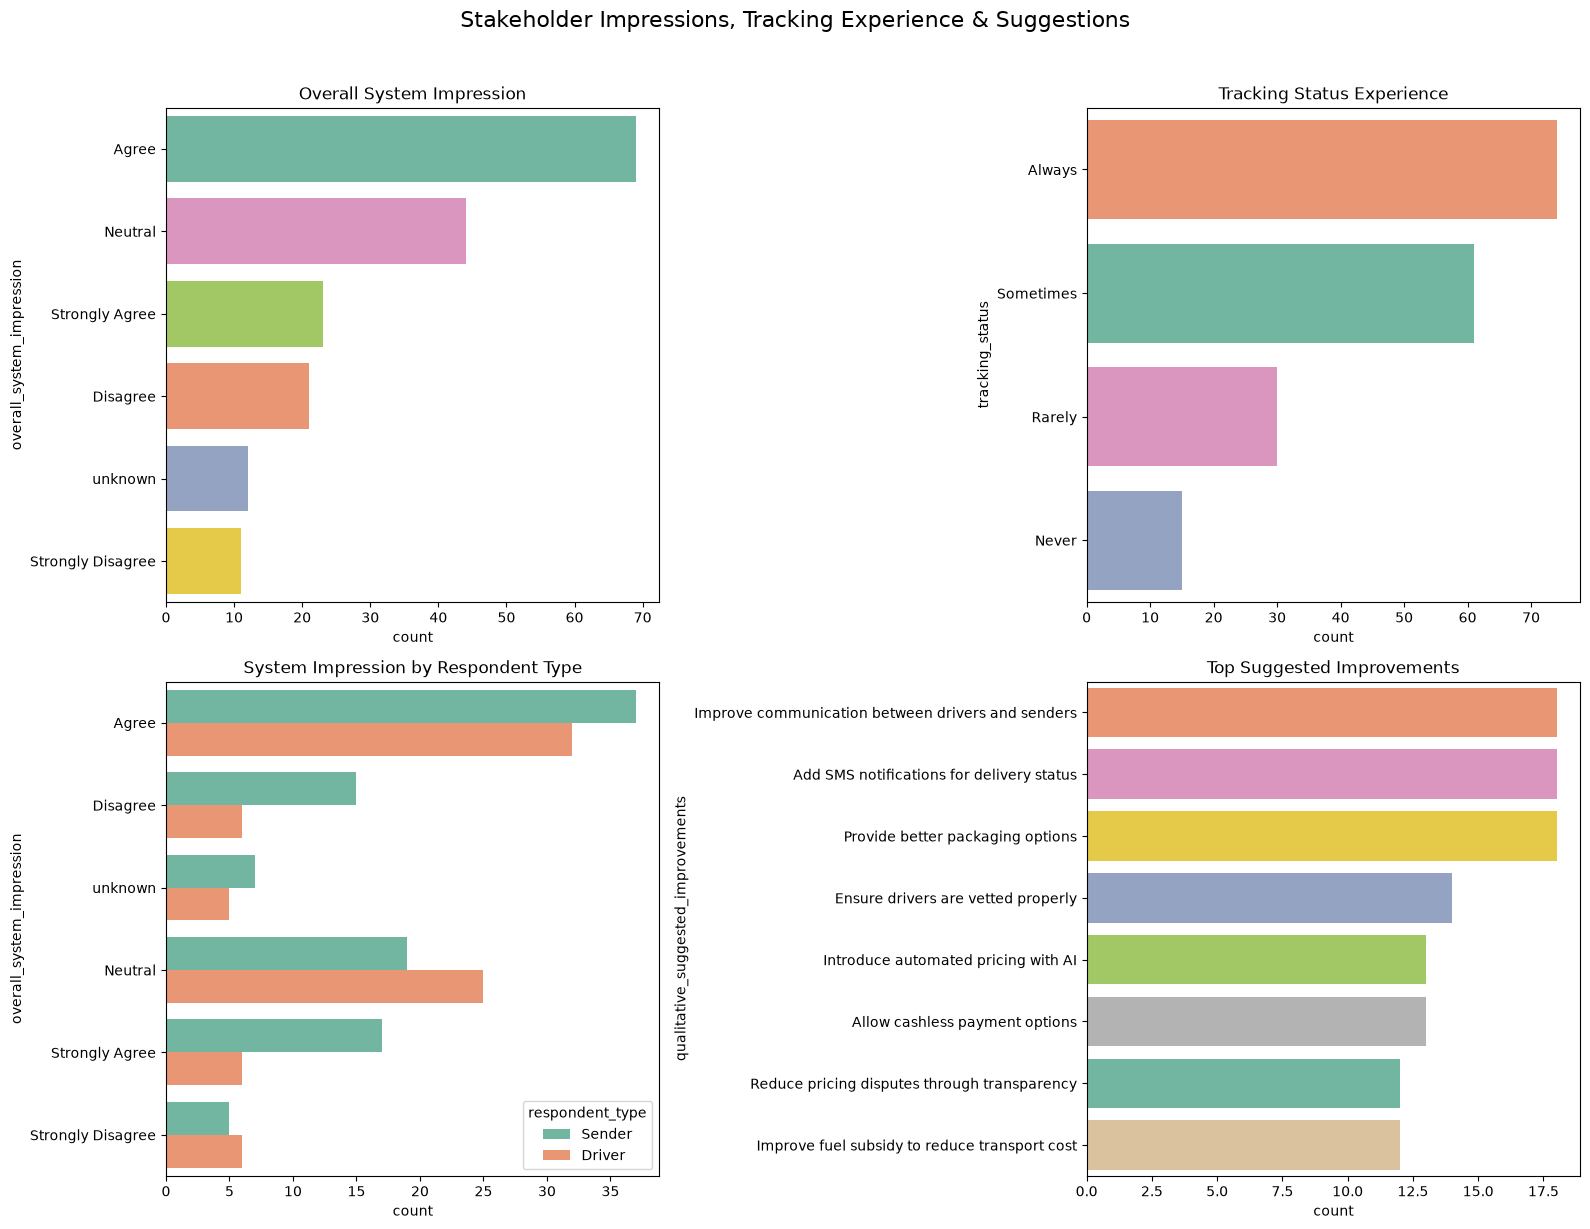

In [48]:
# ============================================================
# RESEARCH QUESTION 5
# System impressions, suggestions & tracking experience
# ============================================================

print("=" * 70)
print("RESEARCH QUESTION 5: System Impressions & Suggestions")
print("=" * 70)

print("\nOverall System Impression:")
print(df['overall_system_impression'].value_counts())

print("\nTracking Status Experience:")
print(df['tracking_status'].value_counts())

print("\nSystem Impression by Tracking Status:")
print(pd.crosstab(df['tracking_status'], df['overall_system_impression'], normalize='index').round(3) * 100)

print("\nSystem Impression by Respondent Type:")
print(pd.crosstab(df['respondent_type'], df['overall_system_impression'], normalize='index').round(3) * 100)

print("\nTop Qualitative Suggested Improvements:")
print(df['qualitative_suggested_improvements'].value_counts().head(15))

# Visualization
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.countplot(data=df, y='overall_system_impression', hue="overall_system_impression", legend=False, 
              order=df['overall_system_impression'].value_counts().index, ax=axes[0,0], palette='Set2')
axes[0,0].set_title('Overall System Impression')

sns.countplot(data=df, y='tracking_status', hue="tracking_status", legend=False,
              order=df['tracking_status'].value_counts().index, ax=axes[0,1], palette='Set2')
axes[0,1].set_title('Tracking Status Experience')

sns.countplot(data=df, y='overall_system_impression', hue='respondent_type', ax=axes[1,0], palette='Set2')
axes[1,0].set_title('System Impression by Respondent Type')

# Top 8 suggestions for readability
top_suggestions = df['qualitative_suggested_improvements'].value_counts().head(8).index
sns.countplot(data=df[df['qualitative_suggested_improvements'].isin(top_suggestions)],
              y='qualitative_suggested_improvements', hue="qualitative_suggested_improvements", legend=False,
              order=top_suggestions, ax=axes[1,1], palette='Set2')
axes[1,1].set_title('Top Suggested Improvements')

plt.suptitle('Stakeholder Impressions, Tracking Experience & Suggestions', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "Stakeholder_Impressions_Tracking_Experience_&_Suggestions.png", dpi=300, bbox_inches='tight')
plt.show()

In [49]:
data["overall_system_impression"].value_counts(), data["overall_system_impression"].isnull().sum()

(overall_system_impression
 Agree                75
 Neutral              50
 Strongly Agree       27
 Disagree             23
 unknown              14
 Strongly Disagree    11
 Name: count, dtype: int64,
 np.int64(0))

# Machine Learning - Baseline

In [ ]:
"""
Rule-based pricing formula - the benchmark the ML model must beat.
Coefficients:
  B(small_car)=750, B(big_bus)=950
  r_d(small_car)=11 NGN/km, r_d(big_bus)=9 NGN/km
  weight threshold=5 kg; r_w(small_car)=70 NGN/kg, r_w(big_bus)=35 NGN/kg
  F0=1050 NGN/litre; route-risk step=0.09
  weekend uplift=12% of subtotal; festive uplift=25% of subtotal
  hard floor=NGN 1,500
"""

def calculate_baseline_price(
    weight_kg: float,
    distance_km: float,
    vehicle_type: str,
    route_risk: int,
    is_weekend: bool,
    is_festive: bool,
    fuel_price_per_litre: float,
) -> dict:
    """
    Deterministic baseline fare.
    """
    BASE_RATE = {"small_car": 750.0, "big_bus": 950.0}
    DISTANCE_RATE = {"small_car": 11.0, "big_bus": 9.0}
    WEIGHT_THRESHOLD = 5.0
    WEIGHT_RATE = {"small_car": 70.0, "big_bus": 35.0}
    REFERENCE_FUEL_PRICE = 1050.0
    RISK_STEP = 0.09
    WEEKEND_UPLIFT = 0.12
    FESTIVE_UPLIFT = 0.25
    PRICE_FLOOR = 1500.0

    base = BASE_RATE[vehicle_type]
    distance_cost = distance_km * DISTANCE_RATE[vehicle_type]
    weight_cost = max(0.0, weight_kg - WEIGHT_THRESHOLD) * WEIGHT_RATE[vehicle_type]
    fuel_multiplier = float(fuel_price_per_litre) / REFERENCE_FUEL_PRICE
    subtotal = (base + distance_cost + weight_cost) * fuel_multiplier
    risk_surcharge = subtotal * ((int(route_risk) - 1) * RISK_STEP)
    if is_festive:
        demand_surcharge = subtotal * FESTIVE_UPLIFT
    elif is_weekend:
        demand_surcharge = subtotal * WEEKEND_UPLIFT
    else:
        demand_surcharge = 0.0
    raw = subtotal + risk_surcharge + demand_surcharge
    total = max(PRICE_FLOOR, raw)
    return {
        "total": round(total, 2),
        "breakdown": {
            "base_fare": round(base, 2),
            "distance_cost": round(distance_cost, 2),
            "weight_cost": round(weight_cost, 2),
            "fuel_multiplier": round(fuel_multiplier, 4),
            "risk_surcharge": round(risk_surcharge, 2),
            "demand_surcharge": round(demand_surcharge, 2),
            "price_floor_applied": raw < PRICE_FLOOR,
        },
    }



# Build Feature Matrix

In [51]:
X = df[features].copy()
y = df['price_ngn']

# Split data 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training shape = X_train shape: {X_train.shape}, percentage: {((len(X_train)/len(df))*100)}% | y_train shape: {y_train.shape}, percentage: {(len(y_train)/len(df))*100}%")
print(f"Testing Shape = X_test Shape: {X_test.shape}, percentage: {(len(X_test)/len(df))*100}% | y_test shape: {y_test.shape}, percentage: {(len(y_test)/len(df))*100}%")
print("\nTraining Data (X_train) Head:")
display(X_train.head())

Training shape = X_train shape: (144, 22), percentage: 80.0% | y_train shape: (144,), percentage: 80.0%
Testing Shape = X_test Shape: (36, 22), percentage: 20.0% | y_test shape: (36,), percentage: 20.0%

Training Data (X_train) Head:


,day_of_the_week,fuel_price_per_litre,weight_kg,volume_cm3,density,is_weekend,vehicle_type_encoded,is_festive_period,qualitative_suggested_improvements,overall_system_impression,pricing_determination_metric,top_challenge,weather_delay_experience,tracking_status,parcel_weight,package_size,vehicle_type,respondent_type,age_group,destination,day_name,origin_park
127,4,1225.0,NaN,360000,NaN,0,1,False,Reduce delays during festive periods,Neutral,unknown,Pricing disputes,Heavy rain,Always,very heavy,extra_large,big_bus,Driver,36–40,Lagos,Thursday,Ondo garage Akure
69,6,1275.0,3.5,30000,116.666667,1,1,False,Allow cashless payment options,Disagree,unknown,Police checkpoints,Harmattan,Sometimes,light,small,big_bus,Driver,36–40,Ife,Saturday,Cathedral Park Akure
71,6,1275.0,10.0,70000,142.857143,1,1,False,Allow cashless payment options,Neutral,Distance only,Inaccurate addresses,Harmattan,Sometimes,medium,medium,big_bus,Sender,41–50,Warri,Saturday,Roadblock Akure
32,4,905.0,3.5,30000,116.666667,0,1,False,Track parcels end-to-end,Strongly Disagree,"Distance, Weight, Fuel cost combo",Poor road infrastructure,Heavy rain,Always,light,small,big_bus,Driver,Above 50,Lagos,Thursday,Ondo garage Akure
13,3,1102.5,22.0,175000,125.714286,0,1,False,Ensure drivers are vetted properly,Agree,Type of goods,Poor network connectivity,Heavy rain,Rarely,heavy,large,big_bus,Sender,26–35,Ondo,Wednesday,Ondo garage Akure


# MultiModel Comparison

In [52]:
# Preprocessing pipeline for linear models
linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="mean")),
            ("scaler", StandardScaler()),
        ]), numerical_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_features),
    ],
    remainder="drop",
)

# Preprocessing pipeline for tree based models
numerical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean'))
])
categorical_preprocessor = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
tree_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_preprocessor, numerical_features),
        ('cat', categorical_preprocessor, categorical_features)
    ],
    remainder='drop',
    verbose_feature_names_out=False
)

# Shared Evaluation Function
def evaluate_regressor(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    pred_tr = model.predict(X_tr)
    pred_te = model.predict(X_te)
    return {
        "Model": name,
        "Train R²": r2_score(y_tr, pred_tr),
        "Test R²":  r2_score(y_te, pred_te),
        "Train MAE": mean_absolute_error(y_tr, pred_tr),
        "Test MAE":  mean_absolute_error(y_te, pred_te),
        "Train RMSE": root_mean_squared_error(y_tr, pred_tr),
        "Test RMSE":  root_mean_squared_error(y_te, pred_te),
    }

# -------- TRAIN MODELS ------------
results = []
# Linear Regression
lr = Pipeline([
    ("preprocessor", linear_preprocessor),
    ("regressor", LinearRegression()),
])
results.append(evaluate_regressor("Linear Regression", lr, X_train, y_train, X_test, y_test))

# --- Ridge (optional, more stable with one-hot) ---
ridge = Pipeline([
    ("preprocessor", linear_preprocessor),
    ("regressor", Ridge(alpha=1.0, random_state=42)),
])
results.append(evaluate_regressor("Ridge", ridge, X_train, y_train, X_test, y_test))

# --- Random Forest ---
rf = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )),
])
results.append(evaluate_regressor("Random Forest", rf, X_train, y_train, X_test, y_test))

# --- LightGBM ---
lgbm = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("regressor", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbose=-1,
    )),
])
results.append(evaluate_regressor("LightGBM", lgbm, X_train, y_train, X_test, y_test))

# XGBoost & MLP

In [53]:
# Train xgboost model
xgb_model = Pipeline(steps=[
    ('preprocessor', tree_preprocessor),
    ('regressor', XGBRegressor(
        n_estimators=700,
        max_depth=3,
        eval_metric='mae',
        learning_rate=0.01,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=0.1,      # L1 — helps with sparse informal data
        reg_lambda=1.0,     # L2
        random_state=42,
        n_jobs=-1
    ))
])
xgb_model.fit(X_train, y_train)
results.append(evaluate_regressor("XGBoost", xgb_model, X_train, y_train, X_test, y_test))

# --- Optional: shallow MLP ---
mlp = Pipeline([
    ("preprocessor", linear_preprocessor),
    ("regressor", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        max_iter=1000,
        random_state=42,
        early_stopping=True,
        validation_fraction=0.15,
    )),
])
results.append(evaluate_regressor("MLP (neural net)", mlp, X_train, y_train, X_test, y_test))

comparison_df = pd.DataFrame(results).sort_values("Test RMSE")
display(comparison_df.round(4))
comparison_df.to_csv(PROJECT_ROOT / "notebook outputs" / "model_comparison_results.csv", index=False)
print(comparison_df.round(4).to_string(index=False))

c:\Users\USER\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Train R²,Test R²,Train MAE,Test MAE,Train RMSE,Test RMSE
4,XGBoost,0.9562,0.8478,427.3550,699.3646,527.2742,820.1469
1,Ridge,0.9144,0.7802,608.6556,774.6107,737.2497,985.6497
2,Random Forest,0.8849,0.7651,644.7750,837.6507,854.7796,1018.8984
0,Linear Regression,0.9220,0.7146,585.3836,908.8032,703.6473,1123.1128
5,MLP (neural net),0.6494,0.5316,1212.8672,1189.6465,1491.7460,1438.9197
3,LightGBM,0.9205,0.4652,568.4349,1265.5046,710.3832,1537.5540


            Model  Train R²  Test R²  Train MAE  Test MAE  Train RMSE  Test RMSE
          XGBoost    0.9562   0.8478   427.3550  699.3646    527.2742   820.1469
            Ridge    0.9144   0.7802   608.6556  774.6107    737.2497   985.6497
    Random Forest    0.8849   0.7651   644.7750  837.6507    854.7796  1018.8984
Linear Regression    0.9220   0.7146   585.3836  908.8032    703.6473  1123.1128
 MLP (neural net)    0.6494   0.5316  1212.8672 1189.6465   1491.7460  1438.9197
         LightGBM    0.9205   0.4652   568.4349 1265.5046    710.3832  1537.5540


# Model Comparison Visualization

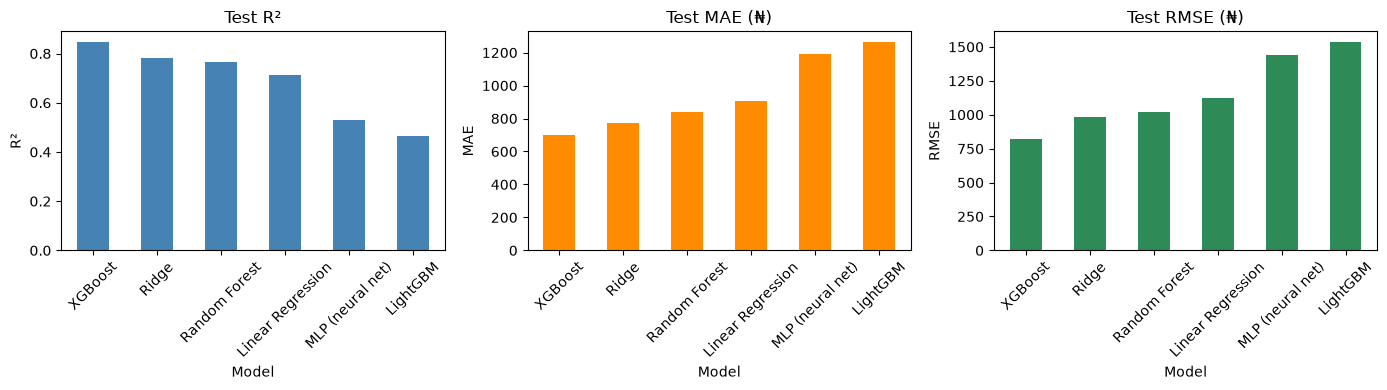

In [54]:
plot_df = comparison_df.set_index("Model")[["Test R²", "Test MAE", "Test RMSE"]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
plot_df["Test R²"].plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Test R²"); axes[0].set_ylabel("R²"); axes[0].tick_params(axis="x", rotation=45)

plot_df["Test MAE"].plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Test MAE (₦)"); axes[1].set_ylabel("MAE"); axes[1].tick_params(axis="x", rotation=45)

plot_df["Test RMSE"].plot(kind="bar", ax=axes[2], color="seagreen")
axes[2].set_title("Test RMSE (₦)"); axes[2].set_ylabel("RMSE"); axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "model_comparison_barplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Feature Importance

,features,importance
0,vehicle_type_encoded,1.850299e+07
1,volume_cm3,7.232955e+06
2,weight_kg,6.021038e+06
3,top_challenge,5.554038e+06
4,destination,5.110660e+06
5,tracking_status,4.212734e+06
6,day_of_the_week,3.957946e+06
7,age_group,3.834139e+06
8,pricing_determination_metric,3.752266e+06
9,is_weekend,3.407851e+06


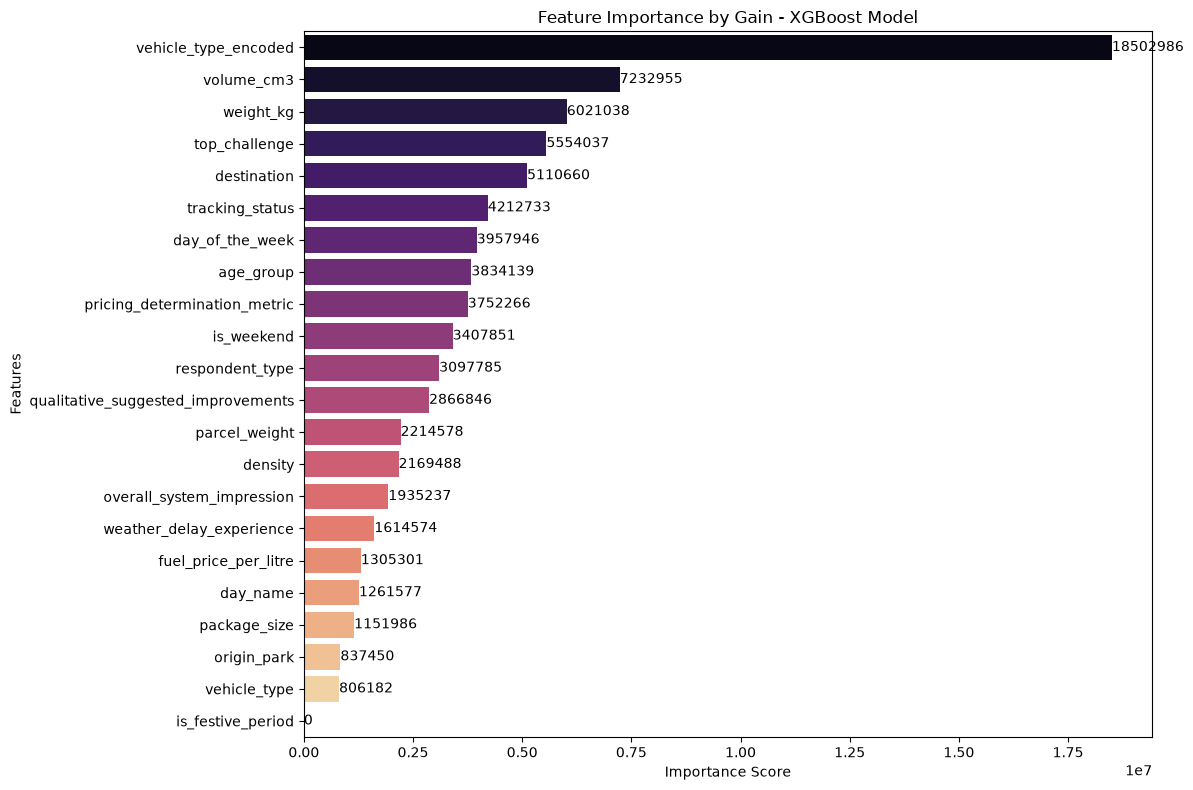

In [55]:
# Feature Importance extraction and visualization
booster = xgb_model.named_steps['regressor'].get_booster()
gain = booster.get_score(importance_type='gain')  # dict: {'f0': val, ...}
# map to feature names from your preprocessor
names = X_train.columns # tree_preprocessor.get_feature_names_out()
feature_importance = (
    pd.DataFrame({'features': names, 'importance': [gain.get(f'f{i}', 0) for i in range(len(names))]})
      .sort_values('importance', ascending=False).reset_index(drop=True)
)
display(feature_importance.head(20))

# Visualization
plt.figure(figsize=(12, 8))
sns.barplot(x="importance", y="features", data=feature_importance, hue="features", palette="magma", errorbar=None, legend=False)
plt.title("Feature Importance by Gain - XGBoost Model")
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## SHAP

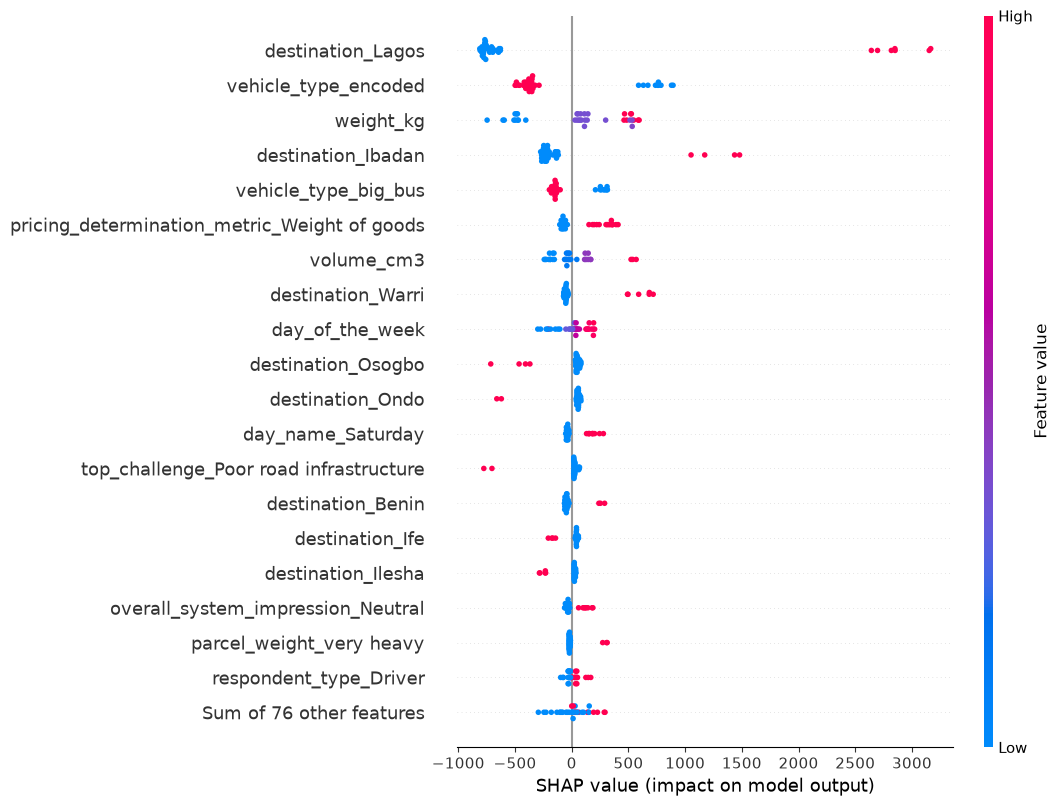

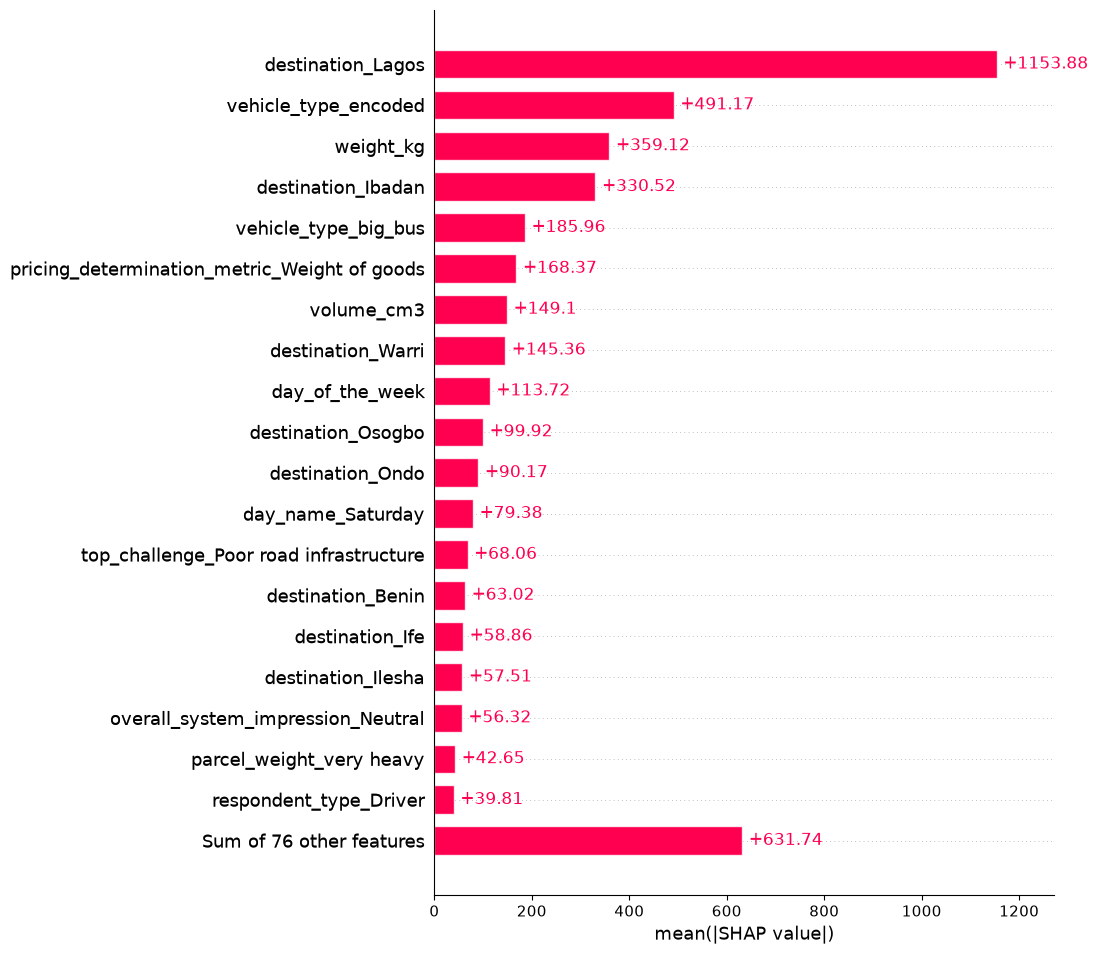

In [56]:
# Transform the test data using the fitted preprocessing step
X_test_processed = xgb_model.named_steps["preprocessor"].transform(X_test)
feature_names = xgb_model.named_steps["preprocessor"].get_feature_names_out()

# Extract the underlying fitted XGBoost model
xgb_estimator = xgb_model.named_steps["regressor"]

explainer = shap.TreeExplainer(
    xgb_estimator,
    feature_perturbation="tree_path_dependent",
)

shap_values = explainer(X_test_processed)
shap_values.feature_names = feature_names.tolist()

shap.plots.beeswarm(shap_values, max_display=20)
shap.plots.bar(shap_values, max_display=20)

# Performance of XGBoost Across different cohorts


===== Cohort: origin_park =====
     cohort                value  n        mae       rmse       r2
origin_park Cathedral Park Akure  3 493.135498 541.835693 0.843467
origin_park      Roadblock Akure 10 507.116791 655.183228 0.785753
origin_park    Ondo garage Akure 10 703.599426 813.727905 0.917958
origin_park      Northgate Akure  6 878.517090 975.150635 0.678894
origin_park  Ilesha garage Akure  7 902.779297 979.403564 0.683273
Average cohort RMSE: 793.06
Average cohort MAE:  697.03
Average cohort R^2:  0.78

===== Cohort: package_size =====
      cohort       value  n        mae       rmse       r2
package_size extra_large  3 440.626129 575.403992 0.148626
package_size    envelope  1 591.523438 591.523438      NaN
package_size       large  8 551.672485 654.564148 0.780684
package_size      medium 14 768.130188 875.278442 0.891677
package_size       small 10 809.652161 933.739624 0.636479
Average cohort RMSE: 726.10
Average cohort MAE:  632.32
Average cohort R^2:  0.61

===== Cohort

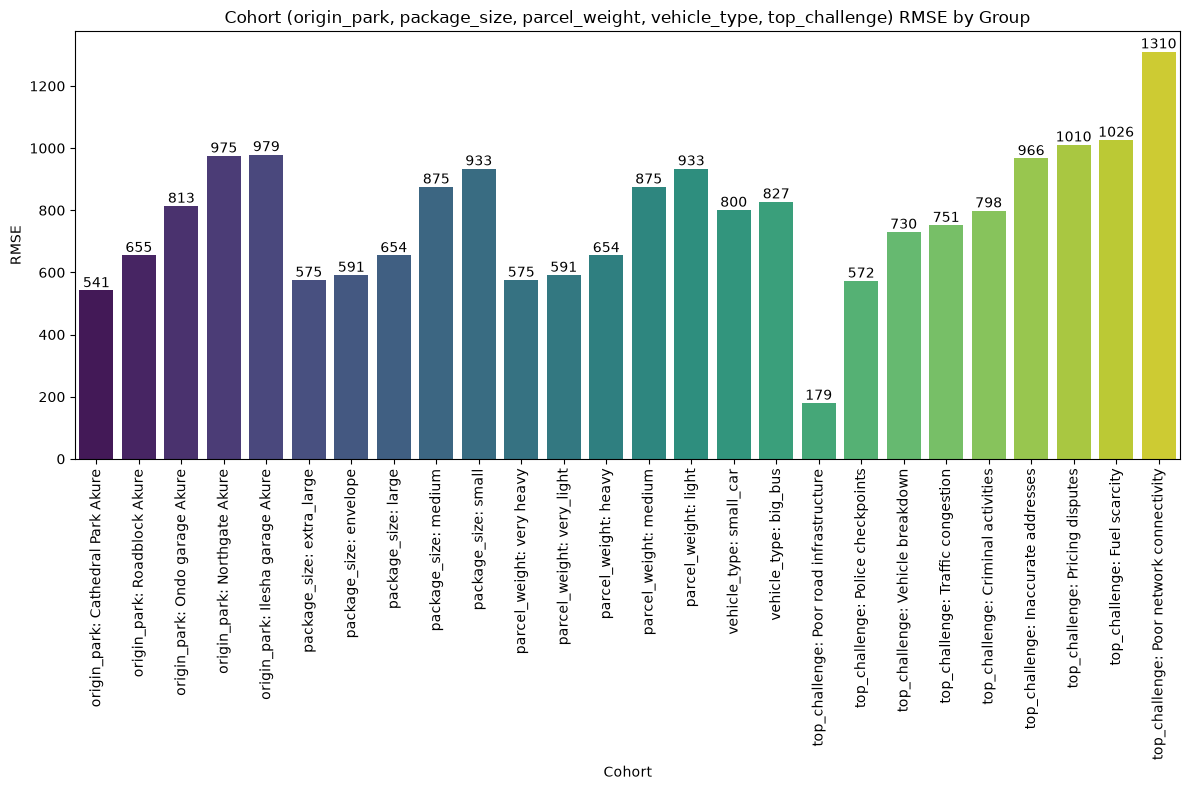

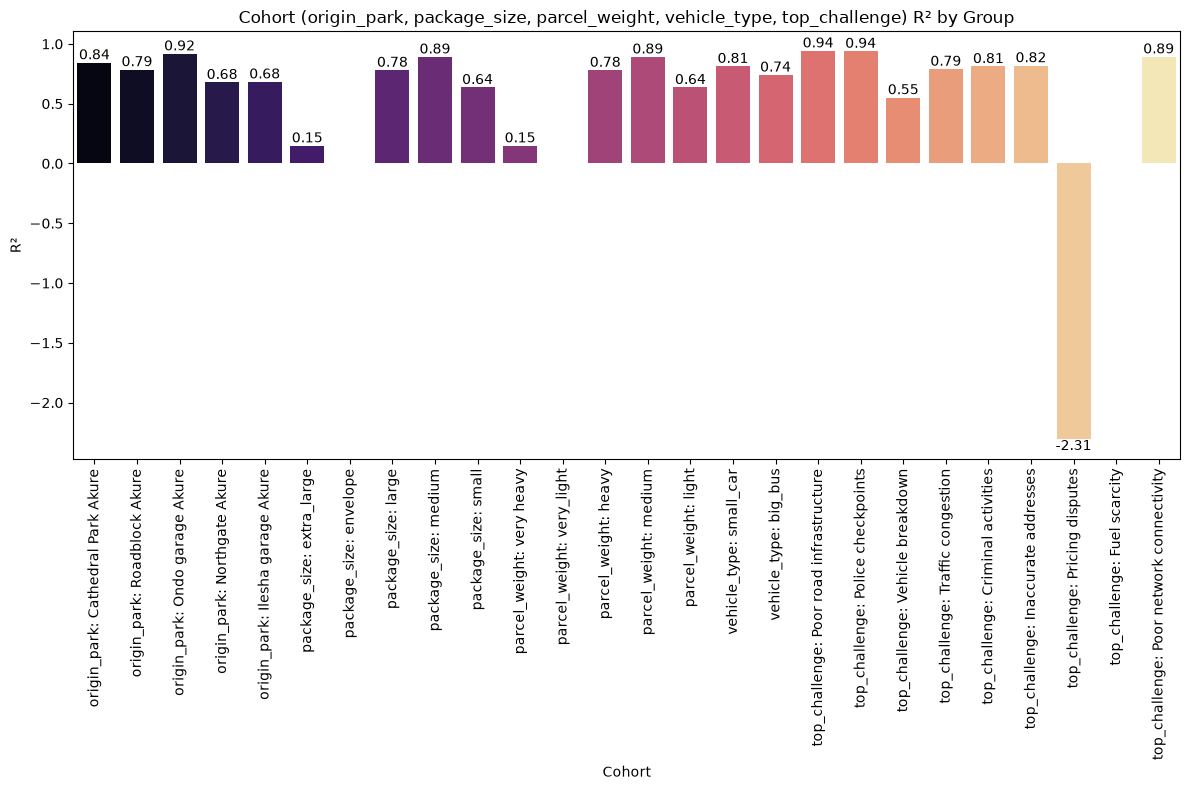

In [57]:
# Cohort-based evaluation of the trained XGBoost model
cohort_columns = ['origin_park', 'package_size', 'parcel_weight', 'vehicle_type', 'top_challenge']

# Evaluate each cohort and store all metrics in one table (using test partition only)
all_cohort_results = []
# cohort_idx_base = X_test.index
for cohort in cohort_columns:
    results = []
    for value in sorted(X_test[cohort].dropna().unique()):
        cohort_idx = X_test.index[X_test[cohort] == value]
        if len(cohort_idx) == 0:
            continue

        X_cohort = X_test.loc[cohort_idx]
        y_cohort = y_test.loc[cohort_idx]
        pred = xgb_model.predict(X_cohort)

        results.append({
            'cohort': cohort,
            'value': value,
            'n': len(y_cohort),
            'mae': mean_absolute_error(y_cohort, pred),
            'rmse': root_mean_squared_error(y_cohort, pred),
            'r2': r2_score(y_cohort, pred) if len(y_cohort) >= 2 else np.nan,
        })

    cohort_df = pd.DataFrame(results).sort_values(['rmse', 'mae'], ascending=True)
    all_cohort_results.append(cohort_df)

    print(f"\n===== Cohort: {cohort} =====")
    print(cohort_df.head(10).to_string(index=False))
    print(f"Average cohort RMSE: {cohort_df['rmse'].mean():.2f}")
    print(f"Average cohort MAE:  {cohort_df['mae'].mean():.2f}")
    print(f"Average cohort R^2:  {cohort_df['r2'].mean():.2f}")

# Visual summary for readability
summary_df = pd.concat(all_cohort_results, ignore_index=True)
summary_df['cohort_label'] = summary_df['cohort'] + ': ' + summary_df['value'].astype(str)

plt.figure(figsize=(12, 8))
sns.barplot(data=summary_df, y='rmse', x='cohort_label', palette='viridis', hue="cohort_label", legend=False)
plt.title('Cohort (origin_park, package_size, parcel_weight, vehicle_type, top_challenge) RMSE by Group')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%d', label_type='edge')
plt.ylabel('RMSE')
plt.xlabel('Cohort')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / 'cohort_RMSE_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 8))
sns.barplot(data=summary_df, y='r2', x='cohort_label', palette='magma', hue="cohort_label", legend=False)
plt.title('Cohort (origin_park, package_size, parcel_weight, vehicle_type, top_challenge) R² by Group')
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.2f', label_type='edge')
plt.ylabel('R²')
plt.xlabel('Cohort')
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "notebook outputs" / 'cohort_R2_by_group.png', dpi=300, bbox_inches='tight')
plt.show()

In [58]:
X_test.shape 

(36, 22)